<a href="https://colab.research.google.com/github/Jerefilms/DEEP-LEARNING/blob/main/notebook2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
%%bash
pip install -U torchao

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 14.3 MB/s  0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0


In [ ]:
# Reiniciar el entorno de ejecución automáticamente para aplicar la nueva versión de torchao
import os
os.kill(os.getpid(), 9)

W1125 00:49:25.186000 2616 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1125 00:49:25.251000 2616 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
Unable to import `torchao` Tensor objects. This may affect loading checkpoints serialized with `torchao`


Dispositivo en uso: cpu


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


trainable params: 797,184 || all params: 860,318,148 || trainable%: 0.0927
Iniciando fine-tuning con LoRA...
Paso [1/40] | Pérdida MSE: 0.0668
Paso [10/40] | Pérdida MSE: 0.0068
Paso [20/40] | Pérdida MSE: 0.0109
Paso [30/40] | Pérdida MSE: 0.0101
Paso [40/40] | Pérdida MSE: 0.0080
Pesos LoRA guardados en 'lora_weights_sks_style'


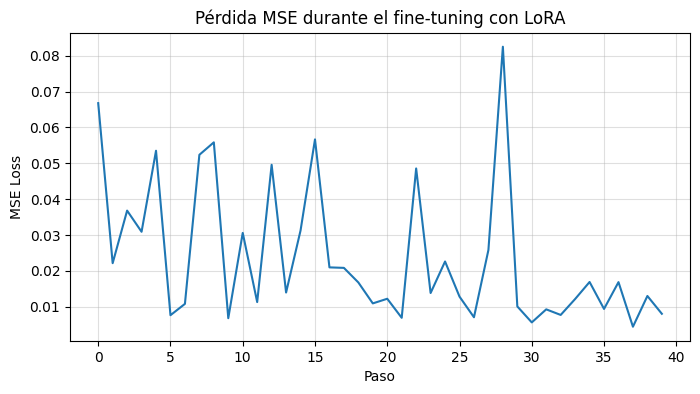

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .
No LoRA keys associated to UNet2DConditionModel found with the prefix='unet'. This is safe to ignore if LoRA state dict didn't originally have any UNet2DConditionModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/is

  0%|          | 0/25 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [1]:
#david celis y harold rueda

import os
import random
import numpy as np
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from diffusers import AutoencoderKL, DDPMScheduler, UNet2DConditionModel, StableDiffusionPipeline
from transformers import CLIPTextModel, CLIPTokenizer
from peft import LoraConfig, get_peft_model

# Fijar semilla para reproducibilidad
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Detectar dispositivo disponible
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dtype_pipe = torch.float16 if device.type == "cuda" else torch.float32
print("Dispositivo en uso:", device)

#cargar componentes
MODEL_ID = "runwayml/stable-diffusion-v1-5"

tokenizer = CLIPTokenizer.from_pretrained(MODEL_ID, subfolder="tokenizer")
text_encoder = CLIPTextModel.from_pretrained(MODEL_ID, subfolder="text_encoder").to(device)
vae = AutoencoderKL.from_pretrained(MODEL_ID, subfolder="vae").to(device)
unet = UNet2DConditionModel.from_pretrained(MODEL_ID, subfolder="unet").to(device)
noise_scheduler = DDPMScheduler.from_pretrained(MODEL_ID, subfolder="scheduler")

# Congelar VAE, Text Encoder y U-Net base; solo entrenaremos los adaptadores LoRA
vae.requires_grad_(False)
text_encoder.requires_grad_(False)
unet.requires_grad_(False)

#inyectar el LORA
lora_config = LoraConfig(
    r=4,
    lora_alpha=4,
    init_lora_weights="gaussian",
    target_modules=["to_k", "to_q", "to_v", "to_out.0"]
)

unet = get_peft_model(unet, lora_config)
unet.print_trainable_parameters()

#crear mini dataset
os.makedirs("custom_dataset", exist_ok=True)
PROMPT_BASE = "a minimalist geometric portrait in sks_style"

colores_lotes = [
    ((30, 41, 59), (56, 189, 248), (244, 63, 94)),
    ((15, 23, 42), (168, 85, 247), (250, 204, 21)),
    ((24, 24, 27), (16, 185, 129), (251, 146, 60)),
    ((30, 27, 75), (236, 72, 153), (34, 211, 238)),
]

rutas_imgs = []
for idx, (bg, c1, c2) in enumerate(colores_lotes):
    img = Image.new("RGB", (256, 256), color=bg)
    draw = ImageDraw.Draw(img)
    draw.ellipse([50, 40, 206, 196], fill=c1)
    draw.rectangle([88, 95, 168, 215], fill=c2)
    ruta = f"custom_dataset/img_{idx}.png"
    img.save(ruta)
    rutas_imgs.append(ruta)

class CustomStyleDataset(Dataset):
    def __init__(self, rutas, prompt, tokenizer, size=256):
        self.rutas = rutas
        self.prompt = prompt
        self.tokenizer = tokenizer
        self.transform = transforms.Compose([
            transforms.Resize((size, size)),
            transforms.ToTensor(),
            transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
        ])

    def __len__(self):
        return len(self.rutas)

    def __getitem__(self, idx):
        img = Image.open(self.rutas[idx]).convert("RGB")
        pixel_values = self.transform(img)
        input_ids = self.tokenizer(
            self.prompt,
            padding="max_length",
            truncation=True,
            max_length=self.tokenizer.model_max_length,
            return_tensors="pt"
        ).input_ids[0]
        return {"pixel_values": pixel_values, "input_ids": input_ids}

dataset = CustomStyleDataset(rutas_imgs, PROMPT_BASE, tokenizer, size=256)
dataloader = DataLoader(dataset, batch_size=2, shuffle=True)

#entramiento en el espacio latente
MAX_STEPS = 40
LR = 1e-4
optimizer = torch.optim.AdamW(unet.parameters(), lr=LR)

unet.train()
losses = []
step = 0

print("Iniciando fine-tuning con LoRA...")
while step < MAX_STEPS:
    for batch in dataloader:
        if step >= MAX_STEPS:
            break

        optimizer.zero_grad()

        # Codificar imágenes a espacio latente y texto a embeddings CLIP
        pixel_values = batch["pixel_values"].to(device)
        with torch.no_grad():
            latentes = vae.encode(pixel_values).latent_dist.sample()
            latentes = latentes * vae.config.scaling_factor
            encoder_hidden_states = text_encoder(batch["input_ids"].to(device))[0]

        # Muestrear ruido y pasos de tiempo aleatorios
        ruido = torch.randn_like(latentes)
        timesteps = torch.randint(
            0, noise_scheduler.config.num_train_timesteps,
            (latentes.shape[0],), device=device
        ).long()

        # Añadir ruido a los latentes y predecirlo con la U-Net + LoRA
        latentes_ruidosos = noise_scheduler.add_noise(latentes, ruido, timesteps)
        ruido_predicho = unet(latentes_ruidosos, timesteps, encoder_hidden_states).sample

        # Calcular pérdida MSE y actualizar pesos LoRA
        loss = F.mse_loss(ruido_predicho.float(), ruido.float(), reduction="mean")
        loss.backward()
        optimizer.step()

        losses.append(loss.item())
        step += 1

        if step % 10 == 0 or step == 1:
            print(f"Paso [{step}/{MAX_STEPS}] | Pérdida MSE: {loss.item():.4f}")

# Guardar los pesos LoRA entrenados
SAVE_DIR = "lora_weights_sks_style"
unet.save_pretrained(SAVE_DIR)
print(f"Pesos LoRA guardados en '{SAVE_DIR}'")

#curva de perdida LORA
plt.figure(figsize=(8, 4))
plt.plot(losses)
plt.title("Pérdida MSE durante el fine-tuning con LoRA")
plt.xlabel("Paso")
plt.ylabel("MSE Loss")
plt.grid(True, alpha=0.4)
plt.show()

# Cargar pipeline completo y aplicar los pesos LoRA guardados
pipe = StableDiffusionPipeline.from_pretrained(
    MODEL_ID,
    torch_dtype=dtype_pipe,
    safety_checker=None
).to(device)

# Corrección: Cargar pesos PEFT LoRA directamente usando load_lora_weights
pipe.load_lora_weights(SAVE_DIR)

prompt_prueba = "a minimalist geometric portrait in sks_style"
generator = torch.Generator(device=device).manual_seed(SEED)

imagen_salida = pipe(
    prompt=prompt_prueba,
    num_inference_steps=25,
    guidance_scale=7.5,
    generator=generator
).images[0]

plt.figure(figsize=(5, 5))
plt.imshow(imagen_salida)
plt.axis("off")
plt.title("Resultado de inferencia con LoRA")
plt.show()